In [11]:
import pandas as pd
import numpy as np

np.random.seed(42)

design_a = np.random.binomial(1, 0.10, 500)
design_b = np.random.binomial(1, 0.13, 500)

df = pd.DataFrame({
    "Design A": design_a,
    "Design B": design_b
})

df.to_csv("ab_testing_data.csv", index=False)

print(df.head())
print("\nDataset Shape:", df.shape)
print("\nConversion Rates:")
print(df.mean() * 100)

   Design A  Design B
0         0         0
1         1         0
2         0         0
3         0         0
4         0         0

Dataset Shape: (500, 2)

Conversion Rates:
Design A    11.0
Design B    12.2
dtype: float64


In [12]:
# Task 1: Descriptive Statistics

print("DESIGN A STATISTICS")
print("Mean:", df["Design A"].mean())
print("Median:", df["Design A"].median())
print("Mode:", df["Design A"].mode()[0])
print("Standard Deviation:", df["Design A"].std())
print("Variance:", df["Design A"].var())

print("\nDESIGN B STATISTICS")
print("Mean:", df["Design B"].mean())
print("Median:", df["Design B"].median())
print("Mode:", df["Design B"].mode()[0])
print("Standard Deviation:", df["Design B"].std())
print("Variance:", df["Design B"].var())

DESIGN A STATISTICS
Mean: 0.11
Median: 0.0
Mode: 0
Standard Deviation: 0.3132031168184137
Variance: 0.09809619238476888

DESIGN B STATISTICS
Mean: 0.122
Median: 0.0
Mode: 0
Standard Deviation: 0.32761358537558516
Variance: 0.10733066132264583


In [13]:
H0 = "Design B does not increase the conversion rate compared to Design A."
H1 = "Design B has a higher conversion rate than Design A."

print("Null Hypothesis (H0):")
print(H0)

print("\nAlternative Hypothesis (H1):")
print(H1)

Null Hypothesis (H0):
Design B does not increase the conversion rate compared to Design A.

Alternative Hypothesis (H1):
Design B has a higher conversion rate than Design A.


In [14]:
from scipy import stats

t_stat, p_value = stats.ttest_ind(
    df["Design A"],
    df["Design B"],
    equal_var=False,
    alternative="less"
)

print("T-Statistic:", t_stat)
print("P-Value:", p_value)

T-Statistic: -0.5920217207803088
P-Value: 0.2769852022890185


In [15]:
# Task 4: Statistical Interpretation

alpha = 0.05

print("Significance Level:", alpha)
print("P-Value:", p_value)

if p_value < alpha:
    print("\nResult: Reject the Null Hypothesis (H0).")
    print("There is a statistically significant difference between Design A and Design B.")
else:
    print("\nResult: Fail to Reject the Null Hypothesis (H0).")
    print("There is not enough evidence of a significant difference between Design A and Design B.")

Significance Level: 0.05
P-Value: 0.2769852022890185

Result: Fail to Reject the Null Hypothesis (H0).
There is not enough evidence of a significant difference between Design A and Design B.


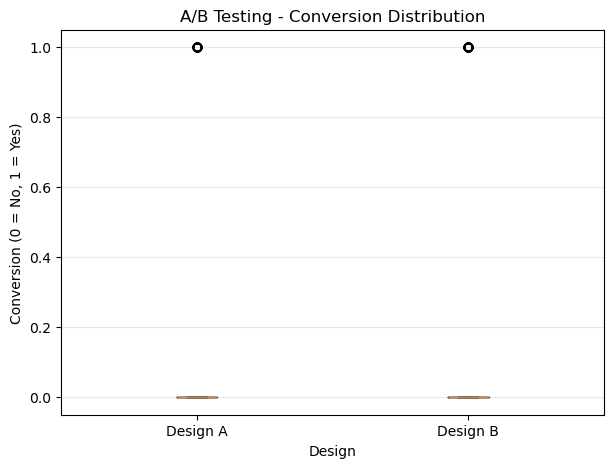

In [16]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 5))

plt.boxplot(
    [df["Design A"], df["Design B"]],
    tick_labels=["Design A", "Design B"]
)

plt.title("A/B Testing - Conversion Distribution")
plt.ylabel("Conversion (0 = No, 1 = Yes)")
plt.xlabel("Design")
plt.grid(axis="y", alpha=0.3)

plt.savefig("ab_testing_boxplot.png", dpi=300, bbox_inches="tight")
plt.show()

In [17]:
report = f"""
A/B TESTING STATISTICAL AUDIT REPORT

Dataset: Simulated Practice Data
Observations: 500 per design

1. CONVERSION RATES
Design A: {df['Design A'].mean() * 100:.2f}%
Design B: {df['Design B'].mean() * 100:.2f}%

2. HYPOTHESIS
H0: Design B does not increase the conversion rate compared to Design A.
H1: Design B has a higher conversion rate than Design A.

3. T-TEST RESULTS
T-Statistic: {t_stat:.4f}
P-Value: {p_value:.4f}

4. CONCLUSION
The p-value ({p_value:.4f}) is greater than the significance level (0.05).
Therefore, we fail to reject the null hypothesis.
There is insufficient evidence to conclude that Design B
has a higher conversion rate than Design A.
"""

print(report)

with open("AB_Testing_Report.txt", "w") as file:
    file.write(report)


A/B TESTING STATISTICAL AUDIT REPORT

Dataset: Simulated Practice Data
Observations: 500 per design

1. CONVERSION RATES
Design A: 11.00%
Design B: 12.20%

2. HYPOTHESIS
H0: Design B does not increase the conversion rate compared to Design A.
H1: Design B has a higher conversion rate than Design A.

3. T-TEST RESULTS
T-Statistic: -0.5920
P-Value: 0.2770

4. CONCLUSION
The p-value (0.2770) is greater than the significance level (0.05).
Therefore, we fail to reject the null hypothesis.
There is insufficient evidence to conclude that Design B
has a higher conversion rate than Design A.



In [18]:
df.to_csv("ab_testing_data.csv", index=False)

print("CSV file saved successfully!")

CSV file saved successfully!
